# UdaPlay - Part 1: Building the Game Knowledge Base (RAG)

UdaPlay is an AI research agent that answers questions about video games. This notebook prepares its
**internal knowledge**: it loads the local game dataset, turns each game into an embeddable document,
stores the documents in a **persistent ChromaDB** collection, and shows that the collection supports
semantic search.

| Step | What happens |
|---|---|
| 1 | Load and validate the game JSON files in `games/` |
| 2 | Format each game into a text document + metadata |
| 3 | Embed with OpenAI and store in ChromaDB (`./chromadb`, persisted to disk) |
| 4 | Query the vector database (semantic search + metadata filters) |
| 5 | Visualize the knowledge base |

The dataset has the 15 games from the project brief plus 5 extra games (`016`-`020`), added to support
richer questions (e.g. comparing Rockstar's or Nintendo's catalogue).

In [1]:
# Only needed in the Udacity workspace (old system sqlite). On your own machine this does nothing.
try:
    __import__("pysqlite3")
    import sys
    sys.modules["sqlite3"] = sys.modules.pop("pysqlite3")
except ImportError:
    pass

## Setup
Load the `.env` file (`OPENAI_API_KEY`, `OPENAI_BASE_URL`, `TAVILY_API_KEY`) and check that all three keys are set.

In [2]:
import os
from dotenv import load_dotenv, find_dotenv

# find_dotenv() finds the .env file in this folder (or a parent folder);
# override=True makes the values in .env win over anything already set.
load_dotenv(find_dotenv(usecwd=True), override=True)

assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY is not set"
assert os.getenv("OPENAI_BASE_URL"), "OPENAI_BASE_URL is not set"
assert os.getenv("TAVILY_API_KEY"), "TAVILY_API_KEY is not set"
print("Environment OK")

Environment OK


In [3]:
import json
from collections import Counter
from pathlib import Path

import chromadb
from chromadb.utils import embedding_functions

from lib.config import embedding_model
from lib.vector_db import COLLECTION_METADATA, game_metadata, game_to_document

## 1. Load and validate the dataset
Each file in `games/` holds one game. The file name (`001`, `002`, ...) becomes the document id.

In [4]:
GAMES_DIR = Path("games")
REQUIRED_FIELDS = {"Name", "Platform", "Genre", "Publisher", "Description", "YearOfRelease"}

games = []
for file in sorted(GAMES_DIR.glob("*.json")):
    game = json.loads(file.read_text(encoding="utf-8"))
    missing = REQUIRED_FIELDS - game.keys()
    assert not missing, f"{file.name} is missing {missing}"
    assert isinstance(game["YearOfRelease"], int), f"{file.name}: YearOfRelease must be an int"
    game["id"] = file.stem
    games.append(game)

print(f"Loaded {len(games)} games\n")
print(f"{'id':<4} {'Name':<42} {'Platform':<36} {'Year':<5} Publisher")
print("-" * 120)
for g in games:
    print(f"{g['id']:<4} {g['Name']:<42} {g['Platform']:<36} {g['YearOfRelease']:<5} {g['Publisher']}")

Loaded 20 games

id   Name                                       Platform                             Year  Publisher
------------------------------------------------------------------------------------------------------------------------
001  Gran Turismo                               PlayStation 1                        1997  Sony Computer Entertainment
002  Grand Theft Auto: San Andreas              PlayStation 2                        2004  Rockstar Games
003  Gran Turismo 5                             PlayStation 3                        2010  Sony Computer Entertainment
004  Pokémon Gold and Silver                    Game Boy Color                       1999  Nintendo
005  Pokémon Ruby and Sapphire                  Game Boy Advance                     2002  Nintendo
006  Super Mario 64                             Nintendo 64                          1996  Nintendo
007  Super Mario World                          Super Nintendo Entertainment System  1990  Nintendo
008  Halo: Combat

In [5]:
print("Platforms:", dict(Counter(g["Platform"] for g in games)))
print("Genres:   ", dict(Counter(g["Genre"] for g in games)))
print("Publishers:", dict(Counter(g["Publisher"] for g in games)))

Platforms: {'PlayStation 1': 1, 'PlayStation 2': 1, 'PlayStation 3': 2, 'Game Boy Color': 1, 'Game Boy Advance': 1, 'Nintendo 64': 2, 'Super Nintendo Entertainment System': 1, 'Xbox': 1, 'Xbox 360': 2, 'PlayStation 4': 2, 'PC': 3, 'Nintendo Switch': 2, 'PlayStation 5': 1}
Genres:    {'Racing': 2, 'Action-adventure': 5, 'Role-playing': 2, 'Platformer': 2, 'First-person shooter': 2, 'Fighting': 1, 'Party': 1, 'Sandbox': 1, 'Action role-playing': 3, 'Life simulation': 1}
Publishers: {'Sony Computer Entertainment': 2, 'Rockstar Games': 3, 'Nintendo': 7, 'Microsoft Game Studios': 3, 'Warner Bros. Interactive Entertainment': 1, 'Mojang': 1, 'Bethesda Softworks': 1, 'Bandai Namco Entertainment': 1, 'CD Projekt': 1}


## 2. Format games into documents
Every game becomes one document. Name, platform, year, genre, and publisher go into the embedded text
(so questions like *"Who published ..."* match on those words), and the same fields are stored as
**metadata** so they can be filtered on and cited exactly.

In [6]:
documents = [game_to_document(g) for g in games]
metadatas = [game_metadata(g) for g in games]
ids = [g["id"] for g in games]

print(documents[1])
print()
print(metadatas[1])

[PlayStation 2] Grand Theft Auto: San Andreas (2004)
Genre: Action-adventure
Publisher: Rockstar Games
Description: An open-world action-adventure game developed by Rockstar North. Players follow Carl "CJ" Johnson as he returns to the fictional state of San Andreas, based on California and Nevada, exploring three cities while completing missions, customizing his character, and building up his gang.

{'Name': 'Grand Theft Auto: San Andreas', 'Platform': 'PlayStation 2', 'Genre': 'Action-adventure', 'Publisher': 'Rockstar Games', 'YearOfRelease': 2004}


## 3. Create the persistent vector database
The embedding function uses `OPENAI_API_KEY` (instead of Chroma's default `CHROMA_OPENAI_API_KEY`) and the
configured base URL. The collection uses cosine distance, so `similarity = 1 - distance`.
`upsert` makes this cell safe to re-run.

In [7]:
chroma_client = chromadb.PersistentClient(path="chromadb")

embedding_fn = embedding_functions.OpenAIEmbeddingFunction(
    api_key_env_var="OPENAI_API_KEY",
    api_base=os.getenv("OPENAI_BASE_URL"),
    model_name=embedding_model(),
)

collection = chroma_client.get_or_create_collection(
    name="udaplay",
    embedding_function=embedding_fn,
    metadata=COLLECTION_METADATA,
)
collection.upsert(ids=ids, documents=documents, metadatas=metadatas)
print(f"Collection '{collection.name}' now holds {collection.count()} documents (persisted in ./chromadb)")

Collection 'udaplay' now holds 20 documents (persisted in ./chromadb)


## 4. Semantic search
Queries are phrased in natural language and don't need to match the stored text word for word.

In [8]:
def semantic_search(query: str, n_results: int = 3, where: dict | None = None) -> None:
    results = collection.query(query_texts=[query], n_results=n_results, where=where)
    print(f"Q: {query}" + (f"   (filter: {where})" if where else ""))
    for doc_id, meta, distance in zip(results["ids"][0], results["metadatas"][0], results["distances"][0]):
        print(f"   {1 - distance:.3f}  [{doc_id}] {meta['Name']} - {meta['Platform']}, "
              f"{meta['YearOfRelease']}, {meta['Publisher']}")
    print()


semantic_search("Who published Grand Theft Auto: San Andreas?")
semantic_search("When was Pokémon Gold and Silver released?")
semantic_search("What platform was Super Mario 64 launched on?")
semantic_search("realistic car racing simulator")
semantic_search("open world fantasy role-playing game with dragons")

Q: Who published Grand Theft Auto: San Andreas?
   0.688  [002] Grand Theft Auto: San Andreas - PlayStation 2, 2004, Rockstar Games
   0.596  [016] Grand Theft Auto V - PlayStation 3, 2013, Rockstar Games
   0.383  [013] Minecraft - PC, 2011, Mojang



Q: When was Pokémon Gold and Silver released?
   0.673  [004] Pokémon Gold and Silver - Game Boy Color, 1999, Nintendo
   0.528  [005] Pokémon Ruby and Sapphire - Game Boy Advance, 2002, Nintendo
   0.293  [007] Super Mario World - Super Nintendo Entertainment System, 1990, Nintendo



Q: What platform was Super Mario 64 launched on?
   0.700  [006] Super Mario 64 - Nintendo 64, 1996, Nintendo
   0.563  [007] Super Mario World - Super Nintendo Entertainment System, 1990, Nintendo
   0.435  [012] The Legend of Zelda: Ocarina of Time - Nintendo 64, 1998, Nintendo



Q: realistic car racing simulator
   0.530  [001] Gran Turismo - PlayStation 1, 1997, Sony Computer Entertainment
   0.460  [003] Gran Turismo 5 - PlayStation 3, 2010, Sony Computer Entertainment
   0.361  [002] Grand Theft Auto: San Andreas - PlayStation 2, 2004, Rockstar Games



Q: open world fantasy role-playing game with dragons
   0.472  [014] The Elder Scrolls V: Skyrim - PC, 2011, Bethesda Softworks
   0.405  [018] Elden Ring - PlayStation 5, 2022, Bandai Namco Entertainment
   0.365  [020] The Witcher 3: Wild Hunt - PC, 2015, CD Projekt



Metadata filters combine with semantic search, e.g. only games on a given platform or after a given year:

In [9]:
semantic_search("adventure game", where={"Platform": "Nintendo 64"})
semantic_search("open world game", where={"YearOfRelease": {"$gte": 2015}})

Q: adventure game   (filter: {'Platform': 'Nintendo 64'})
   0.383  [012] The Legend of Zelda: Ocarina of Time - Nintendo 64, 1998, Nintendo
   0.356  [006] Super Mario 64 - Nintendo 64, 1996, Nintendo



Q: open world game   (filter: {'YearOfRelease': {'$gte': 2015}})
   0.372  [020] The Witcher 3: Wild Hunt - PC, 2015, CD Projekt
   0.365  [019] Animal Crossing: New Horizons - Nintendo Switch, 2020, Nintendo
   0.357  [015] Red Dead Redemption 2 - PlayStation 4, 2018, Rockstar Games



### Persistence check
Open a brand-new client on the same folder and query it. This is exactly how Part 2 loads the knowledge base.

In [10]:
fresh_client = chromadb.PersistentClient(path="chromadb")
reloaded = fresh_client.get_collection("udaplay", embedding_function=embedding_fn)
print(f"Reloaded collection has {reloaded.count()} documents")
print(reloaded.query(query_texts=["Halo on the original Xbox"], n_results=1)["metadatas"][0][0])

Reloaded collection has 20 documents


{'Publisher': 'Microsoft Game Studios', 'Platform': 'Xbox', 'YearOfRelease': 2001, 'Name': 'Halo: Combat Evolved', 'Genre': 'First-person shooter'}


## 5. Visualizing the knowledge base

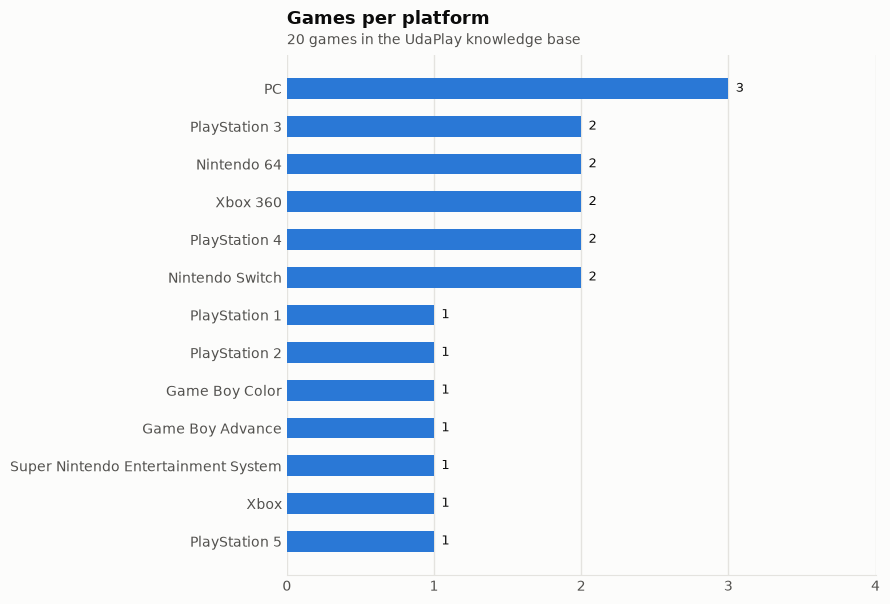

In [11]:
%matplotlib inline
from lib.report import plot_embedding_map, plot_games_per_platform, plot_release_timeline

plot_games_per_platform(games);

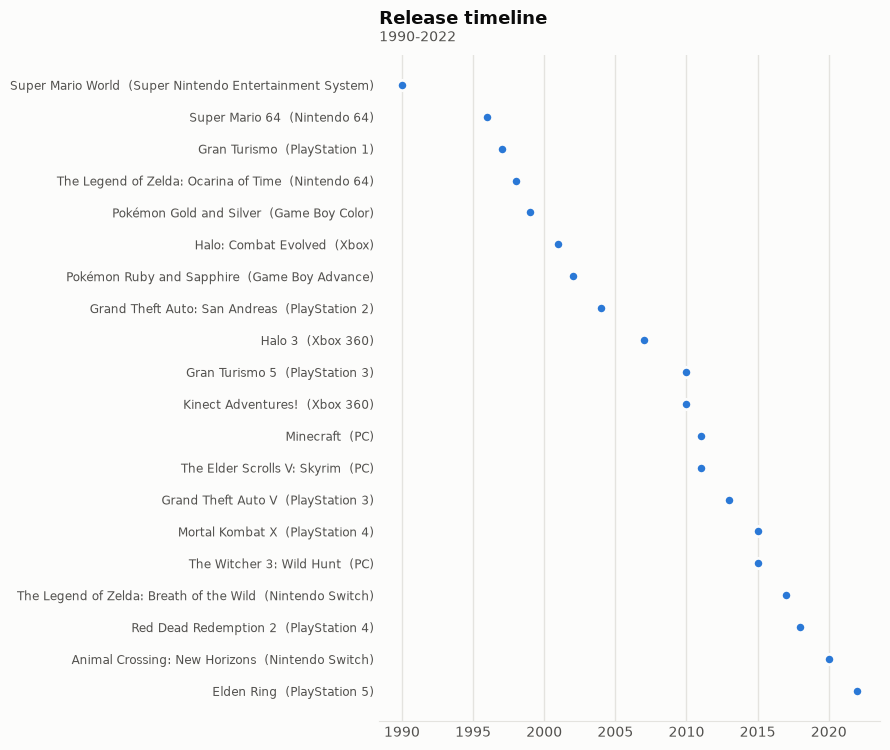

In [12]:
plot_release_timeline(games);

A 2-D PCA projection of the stored embeddings. Games that are semantically similar (e.g. the Gran Turismo or Pokémon titles) sit close together, which is what makes retrieval work.

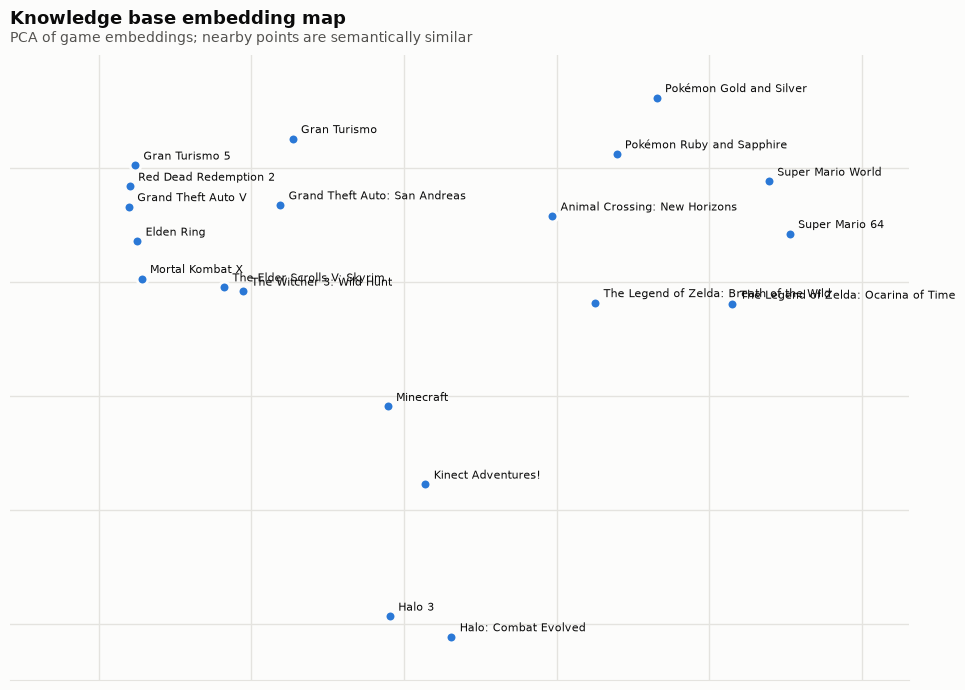

In [13]:
plot_embedding_map(collection);

## Summary
- 20 game records were loaded, validated, and converted into documents with metadata.
- They are embedded with OpenAI embeddings and stored in a **persistent** ChromaDB collection (`./chromadb`, collection `udaplay`).
- Semantic search returns the right game for the three brief questions, and also supports metadata filters.

Continue with **`Udaplay_02_starter_project.ipynb`** to build the agent on top of this collection.